# Wayanad Landslide Prediction - Beginner Baseline

This notebook trains a simple machine-learning model to predict the Landslide label from weather and terrain data. Each section has a short explanation before its code.

> **Important:** This is a learning project using a sample dataset. It is not an official warning system and must not be used to make real-world safety decisions. A random test split does not prove that the model can predict future landslides.

## 1. Import the tools

Pandas reads and organizes the dataset. Scikit-learn splits the data, trains a Random Forest, and measures its predictions. Matplotlib draws the feature-importance chart.

In [24]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from pathlib import Path

## 2. Load and look at the data

The CSV is stored in the project data folder. This path works whether you run the notebook from the project folder or its notebooks folder. The first rows let us check that the file loaded correctly.

In [25]:
file_name = "land_slide.csv"

if Path("data", file_name).exists():
    data_path = Path("data", file_name)
else:
    data_path = Path("..", "data", file_name)

if not data_path.exists():
    raise FileNotFoundError(f"Dataset not found: {data_path.resolve()}")

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
print("\nFirst five rows:")
print(df.head())
print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (600, 8)
Columns: ['Location_ID', 'Max_Temp_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'Rainfall_mm', 'Slope_Angle_Deg', 'Vegetation_Cover', 'Landslide']

First five rows:
   Location_ID  Max_Temp_C  Humidity_Pct  Wind_Speed_kmh  Rainfall_mm  \
0            1        31.2          82.0               6         12.5   
1            2        30.5          85.0               5         45.2   
2            3        28.1          92.0              12        120.4   
3            4        27.5          19.8              15        185.0   
4            5        26.2          19.2              18        240.2   

   Slope_Angle_Deg Vegetation_Cover Landslide  
0               15             High        No  
1               22           Medium        No  
2               35              Low       Yes  
3               38              Low       Yes  
4               42              Low       Yes  

Missing values in each column:
Location_ID         0
Max_Temp_C          0
Humidity_Pct   

## 3. Choose inputs and split the data

The model should learn from weather and terrain, not from Location_ID, which is only an identifier. Landslide is the answer we want the model to predict. Rows with missing values are removed, the text category is changed into simple numeric columns, and the data is divided into training and test sets.

In [26]:
df = df.dropna()

X = df.drop(columns=["Landslide", "Location_ID"])
X = pd.get_dummies(X, columns=["Vegetation_Cover"], dtype=int)
y = df["Landslide"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Features used:", list(X.columns))

Training rows: 480
Test rows: 120
Features used: ['Max_Temp_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'Rainfall_mm', 'Slope_Angle_Deg', 'Vegetation_Cover_High', 'Vegetation_Cover_Low', 'Vegetation_Cover_Medium']


## 4. Train the model

A Random Forest combines the results of many decision trees. Here we use 100 trees. The model learns patterns from the training data; it does not see the test data during training.

In [27]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Model training is complete.")

Model training is complete.


## 5. Check the predictions

Accuracy is the fraction of test examples predicted correctly. The confusion matrix and classification report show how often each Landslide class was predicted correctly or missed. These results describe only this test split. A perfect score does not prove the model is reliable on new places or future events; always check it with independent real-world data.

In [28]:
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nConfusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, predictions))
print("\nClassification report:")
print(
    classification_report(
        y_test,
        predictions,
        target_names=["No landslide", "Landslide"],
        zero_division=0,
    )
)

Accuracy: 1.0

Confusion matrix (actual rows, predicted columns):
[[56  0]
 [ 0 64]]

Classification report:
              precision    recall  f1-score   support

No landslide       1.00      1.00      1.00        56
   Landslide       1.00      1.00      1.00        64

    accuracy                           1.00       120
   macro avg       1.00      1.00      1.00       120
weighted avg       1.00      1.00      1.00       120



## 6. See which features the model used most

Feature importance shows which input columns contributed most to the Random Forest decisions. It does not show that a feature causes landslides, and it should not be treated as a scientific explanation.

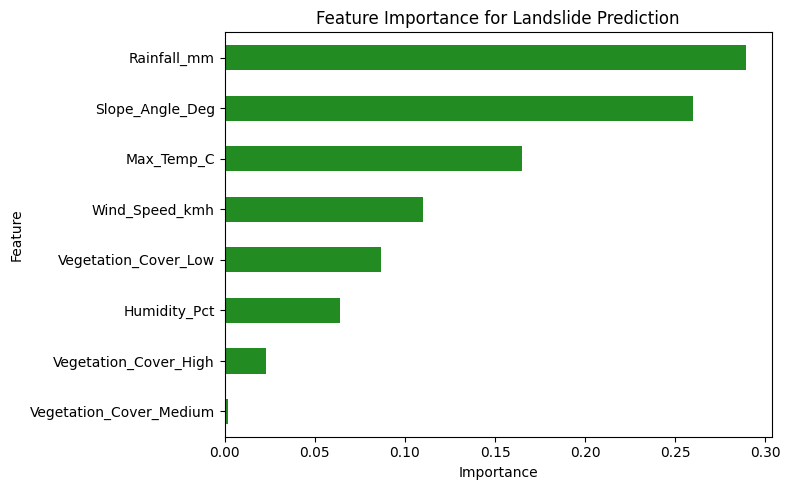

In [29]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns,
).sort_values()

importance.plot(kind="barh", color="forestgreen", figsize=(8, 5))
plt.title("Feature Importance for Landslide Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## What to improve next

- Learn about precision, recall, and why missed landslide cases need careful attention.
- Test on data collected at a later time or from different locations.
- Ask a landslide-domain expert to review the data and results.
- Keep the model as a learning baseline until it has been rigorously validated.

In [30]:
import joblib
MODEL_PATH = Path("landslide_logistic_pipeline.joblib")
joblib.dump(model, MODEL_PATH)
print("Saved to:", MODEL_PATH.resolve())

Saved to: C:\Users\91904\Desktop\ksfe\AI\CODE\Django_React_AI_project\wayanad-landslide-early-warning-system\notebooks\landslide_logistic_pipeline.joblib
